# land prices: data collection and eda

second case on the same ikman.lk ads, this time **land**. the target is the price per perch. it is a different problem from houses: land ads only have a plot size, a land type and a location, so most of what explains the price is the place and what the seller writes about the plot. this notebook gets the data, fixes the price units, removes reposts and has a look at what drives price per perch.

In [1]:
import os, io, glob, ast, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

## 1. getting the data

same kaggle file as the house notebook (already in `../data/raw`). i take every ad with category land or land for sale: 109,169 of the 203,874 ads.

In [2]:
os.environ['KAGGLEHUB_CACHE'] = '../data/raw'
import kagglehub

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    kagglehub.dataset_download('ivantha/sri-lanka-property-ads-dataset')

raw = pd.read_csv(glob.glob('../data/raw/**/properties.csv', recursive=True)[0])
land = raw[raw['category'].isin(['Land', 'Land For Sale']) & (raw['type'] == 'for_sale')].copy()
print(raw.shape, land.shape)

(203874, 26) (109169, 26)


In [3]:
land[['price', 'details', 'location', 'properties']].sample(5, random_state=1)

,price,details,location,properties
181917,"Rs 380,000 per perch",10.0 perches,Horana,"{'Address': 'batuwita', 'Land type': 'Commerci..."
169544,"Rs 54,000,000 total price",90.0 perches,Ambalangoda,"{'Address': 'Akurala, Ambalangoda', 'Land type..."
198535,"Rs 3,500,000 total price",6.5 perches,Meegoda,"{'Land type': 'Commercial, Residential, Other'..."
162731,"Rs 100,000 per perch",160.0 perches,Kandy City,"{'Address': 'à¶±à·\x94à·\x80à¶» ', 'Land type'..."
197927,"Rs 1,500,000 per perch",9.0 perches,Weligama,"{'Land type': 'Other', 'Land size': '9.0 perch..."


## 2. parsing

- **price:** 85,650 ads give a price per perch, 23,023 give a total price and 492 give a price per acre. one column cannot mix those, so everything is turned into rs per perch (total divided by size, per acre divided by 160)
- **size:** mostly perches, a few acres (1 acre is 160 perches)
- **land type:** text like `Commercial, Residential`, split into three 0/1 columns
- **ad text:** a seller writes things like main road, near the highway, clear deed. i search the title, description and address for a few words and make 0/1 columns. these are things a person can tick on a form, so the web app can ask for them too

In [4]:
def parse_dict(s):
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return {}

props = land['properties'].apply(parse_dict)

# land size is in perches or acres, 1 acre = 160 perches
size_text = props.apply(lambda d: d.get('Land size'))
size_num = pd.to_numeric(size_text.str.replace(',', '').str.split().str[0], errors='coerce')
size_perches = np.where(size_text.str.contains('acre', na=False), size_num * 160, size_num)
size_perches = np.where(size_perches > 0, size_perches, np.nan)

# the price is a total, per perch or per acre
amount = pd.to_numeric(land['price'].str.extract(r'Rs ([\d,\.]+)')[0].str.replace(',', ''), errors='coerce')
unit = land['price'].str.extract(r'(per perch|total price|per acre)')[0]
print(unit.value_counts(dropna=False))

0
per perch      85650
total price    23023
per acre         492
NaN                4
Name: count, dtype: int64


In [5]:
per_perch = np.select(
    [unit == 'per perch', unit == 'total price', unit == 'per acre'],
    [amount, amount / size_perches, amount / 160],
    default=np.nan)

land_types = props.apply(lambda d: d.get('Land type', ''))

# words in the ad that a seller would tick on a form
text = (land['ad_title'].fillna('') + ' ' + land['ad_description'].fillna('') + ' ' + props.apply(lambda d: d.get('Address', ''))).str.lower()
keywords = {
    'main_road': 'main road|high level road|highlevel',
    'highway': 'highway|expressway|interchange',
    'clear_deed': 'clear deed|deed|freehold|sinnakkara',
    'near_town': 'near|walking distance|close to|minutes',
    'bare_land': 'bare land',
    'water': 'water',
    'electricity': 'electricity|power',
    'lake_or_beach': 'lake|beach|sea view|river|ocean',
    'paddy': 'paddy|field',
    'investment': 'investment',
}

df = pd.DataFrame({
    'price_per_perch': per_perch,
    'land_size_perches': size_perches,
    'residential': land_types.str.contains('Residential').astype(int),
    'commercial': land_types.str.contains('Commercial').astype(int),
    'agricultural': land_types.str.contains('Agricultural').astype(int),
    'location': land['location'].str.strip().str.title(),
    'district': land['area'].apply(lambda s: parse_dict(s).get('name')),
    'membership_level': land['membership_level'],
    'is_verified': land['is_verified'].astype(int),
    'is_member': land['is_member'],
    'posted_date': pd.to_datetime(land['posted_date'], utc=True, errors='coerce'),
    'user': land['user'],
}).reset_index(drop=True)
for name, pattern in keywords.items():
    df[name] = text.reset_index(drop=True).str.contains(pattern).astype(int)
df['posted_month'] = df['posted_date'].dt.month
df['description_length'] = land['ad_description'].fillna('').str.len().values
df.head()

,price_per_perch,land_size_perches,residential,commercial,agricultural,location,district,membership_level,is_verified,is_member,posted_date,user,main_road,highway,clear_deed,near_town,bare_land,water,electricity,lake_or_beach,paddy,investment,posted_month,description_length
0,5.000000e+04,15.0,1,1,0,Kurunegala City,Kurunegala,premium,0,True,2022-11-10 06:36:19+00:00,f917ed789e936ada5530694ede4edde85fdb53f739c5f6...,0,0,0,0,0,0,0,0,0,0,11.0,458
1,1.600000e+06,18.5,1,0,0,Kelaniya,Gampaha,premium,1,True,2023-01-30 03:24:35+00:00,147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...,0,0,0,0,1,0,0,0,0,0,1.0,173
2,1.700000e+06,12.0,1,0,0,Kelaniya,Gampaha,premium,1,True,2023-01-30 03:24:29+00:00,147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...,0,0,0,0,1,0,0,0,0,0,1.0,173
3,2.260870e+05,11.5,1,0,0,Horana,Kalutara,premium,0,True,2022-10-26 04:28:35+00:00,3490be978dc2c1fc66b53754f84abfeebb826a25d30cd6...,0,0,0,0,0,0,0,0,0,0,10.0,423
4,2.350000e+05,20.0,1,0,0,Horana,Kalutara,premium,0,True,2022-10-26 04:28:11+00:00,3490be978dc2c1fc66b53754f84abfeebb826a25d30cd6...,0,0,0,0,0,0,0,0,0,0,10.0,433


## 3. nulls

nothing much is missing, only `is_member` (836 rows). 4 ads had no usable price (rent per year or negotiable) and a few had no size, so those 7 are dropped.

In [6]:
df.isna().sum().loc[lambda s: s > 0].to_frame('nulls').assign(pct=lambda x: (x['nulls'] / len(df) * 100).round(2))

,nulls,pct
price_per_perch,6,0.01
land_size_perches,3,0.00
is_member,980,0.90
posted_date,2,0.00
posted_month,2,0.00


In [7]:
# the unit was not per perch, total or per acre (rent per year, negotiable)
df = df.dropna(subset=['price_per_perch', 'land_size_perches']).reset_index(drop=True)
print('rows with a usable price and size:', len(df))

rows with a usable price and size: 109162


## 4. reposts

this is the big one. 76,402 ads have the same price per perch, size and location as another ad, so about 70% of the land ads are repeats. the top seller alone posted 9,782 ads and the top 5 sellers posted more than 29,000 between them (there are 6,309 sellers). if i left these in, the same plot would be in both train and test and any model would look much better than it is.

only one ad per price, size and location is kept: 32,760 rows left.

In [8]:
print('exact duplicates:', df.drop(columns='user').duplicated().sum())
core = ['price_per_perch', 'land_size_perches', 'location']
print('same price, size and location:', df.duplicated(core).sum())
print('ads per seller, top 5:', df['user'].value_counts().head(5).tolist(), 'of', df['user'].nunique(), 'sellers')

exact duplicates: 193
same price, size and location: 76402
ads per seller, top 5: [9782, 5994, 5386, 4025, 3960] of 6309 sellers


In [9]:
before = len(df)
df = df.drop_duplicates(core).reset_index(drop=True)
print(f'kept {len(df)} of {before}')

kept 32760 of 109162


## 5. outliers

the table has mistakes: sizes of 142 million perches and prices up to 3.6 billion per perch. price per perch is also very skewed (median rs 470,000, but the 99th percentile is rs 12 million), and on the log scale it is much more even.

i keep price per perch between the 0.5th and 99.5th percentile (rs 3,636 to rs 17,000,000) and sizes from 1 to 1,000 perches. 787 rows removed, 31,973 left.

In [10]:
df[['price_per_perch', 'land_size_perches']].describe(percentiles=[.005, .01, .5, .99, .995]).round(0)

,price_per_perch,land_size_perches
count,3.276000e+04,32760.0
mean,1.295896e+06,6627.0
std,2.085057e+07,821501.0
min,0.000000e+00,0.0
0.5%,3.636000e+03,4.0
1%,7.143000e+03,6.0
50%,4.700000e+05,11.0
99%,1.200000e+07,1840.0
99.5%,1.700000e+07,4800.0
max,3.600000e+09,142222080.0


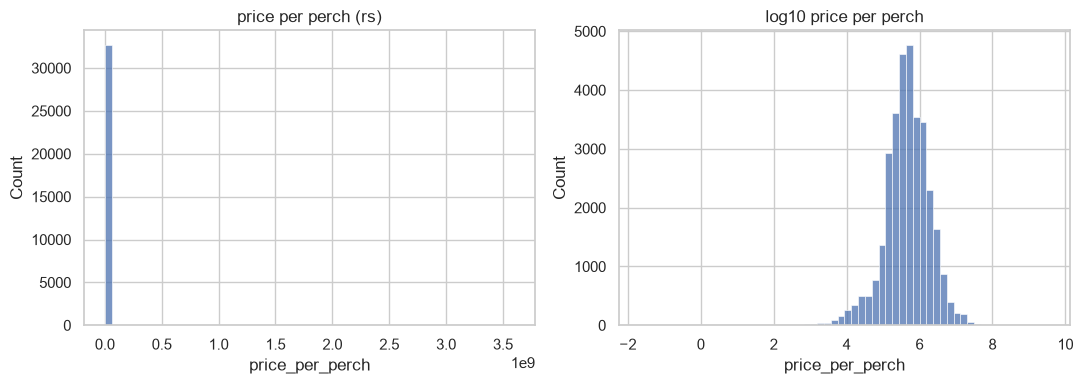

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['price_per_perch'], bins=60, ax=ax[0])
ax[0].set_title('price per perch (rs)')
sns.histplot(np.log10(df['price_per_perch']), bins=60, ax=ax[1])
ax[1].set_title('log10 price per perch')
plt.tight_layout()
plt.show()

In [12]:
low, high = df['price_per_perch'].quantile([.005, .995])
before = len(df)
df = df[df['price_per_perch'].between(low, high) & df['land_size_perches'].between(1, 1000)].reset_index(drop=True)
print(f'price per perch kept between rs {low:,.0f} and rs {high:,.0f}')
print(f'removed {before - len(df)} rows, kept {len(df)}')

price per perch kept between rs 3,636 and rs 17,000,000
removed 787 rows, kept 31973


## 6. what drives the price

**location is the main thing.** colombo has 13,925 ads and a median of rs 955,000 per perch, nuwara eliya is rs 800,000 (only 323 ads), gampaha rs 480,000, kalutara rs 237,500 and most other districts are between rs 85,000 and rs 350,000. a plot in colombo costs about 10 times a plot in monaragala or matale.

**size works the other way.** the correlation of log size with log price per perch is -0.38, bigger plots are cheaper per perch. it is not a straight line though. median price per perch is rs 850,000 for plots up to 6 perches, 628,000 for 6 to 10, 330,000 for 10 to 15, then back up to 600,000 for 15 to 25 and down to 119,000 over 50. the jump at 15 to 25 is probably a few agents selling expensive plots around colombo, so trees should handle this better than a straight line.

In [13]:
by_district = df.groupby('district').agg(ads=('price_per_perch', 'size'), median=('price_per_perch', 'median')).sort_values('median', ascending=False)
by_district[by_district['ads'] >= 30].round(0)

,ads,median
district,,
Colombo,13925,955000.0
Nuwara Eliya,323,800000.0
Gampaha,6080,480000.0
Jaffna,162,350000.0
Kandy,980,325000.0
Batticaloa,184,300000.0
Galle,1072,265000.0
Kalutara,3243,237500.0
Matara,639,235000.0


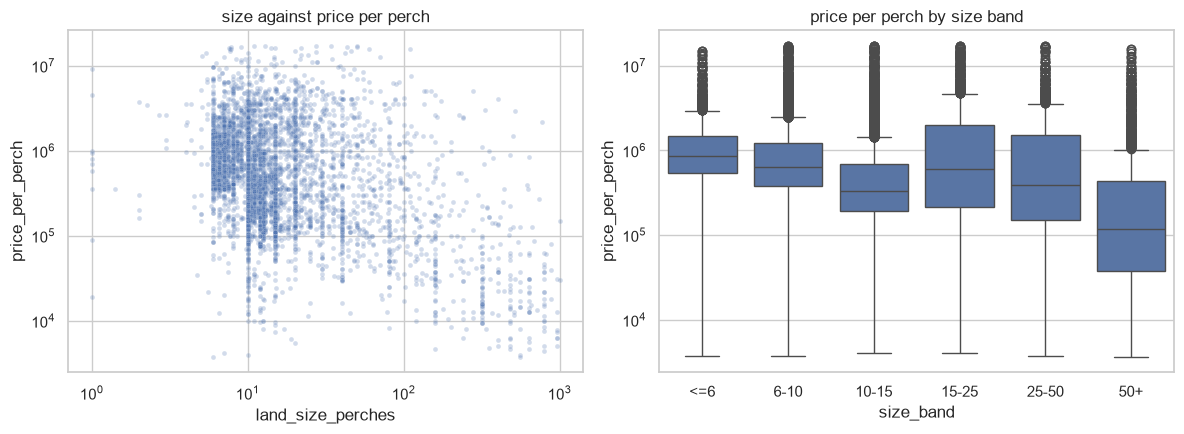

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sample = df.sample(min(6000, len(df)), random_state=1)
sns.scatterplot(data=sample, x='land_size_perches', y='price_per_perch', alpha=.25, s=12, ax=ax[0])
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_title('size against price per perch')
df['size_band'] = pd.cut(df['land_size_perches'], [0, 6, 10, 15, 25, 50, 1000], labels=['<=6', '6-10', '10-15', '15-25', '25-50', '50+'])
sns.boxplot(data=df, x='size_band', y='price_per_perch', ax=ax[1])
ax[1].set_yscale('log')
ax[1].set_title('price per perch by size band')
plt.tight_layout()
plt.show()

**land type matters.** residential land has a median of rs 520,000 and residential plus commercial rs 550,000, commercial only is higher at rs 800,000. anything that includes agricultural is much cheaper, around rs 170,000 (correlation -0.33).

**ad words.** the median price per perch is higher when the ad says near (rs 875,000 against 450,000, 11% of ads), main road (950,000 against 455,000, 6%), highway (785,000 against 460,000) or clear deed (700,000 against 475,000). bare land ads are 3% and have a median of 2 million. these gaps are partly just colombo, since colombo sellers write these words more, so i can't tell yet how much is the words and how much is the place. the models will have to show that.

In [15]:
types = df.assign(land_use=df[['residential', 'commercial', 'agricultural']].apply(
    lambda r: '+'.join([n for n in ['residential', 'commercial', 'agricultural'] if r[n]]) or 'other only', axis=1))
types.groupby('land_use')['price_per_perch'].agg(['size', 'median']).sort_values('size', ascending=False).head(6).round(0)

,size,median
land_use,,
residential,16395,520000.0
residential+commercial,10625,550000.0
residential+commercial+agricultural,1630,175000.0
residential+agricultural,998,170000.0
commercial,988,800000.0
other only,623,190000.0


In [16]:
rows = []
for k in keywords:
    yes, no = df.loc[df[k] == 1, 'price_per_perch'], df.loc[df[k] == 0, 'price_per_perch']
    rows.append({'keyword': k, 'ads with it %': round(df[k].mean() * 100, 1), 'median with': yes.median(), 'median without': no.median()})
pd.DataFrame(rows).sort_values('ads with it %', ascending=False).round(0)

,keyword,ads with it %,median with,median without
3,near_town,11.0,875000.0,450000.0
0,main_road,6.0,950000.0,455200.0
5,water,4.0,600000.0,473846.0
1,highway,4.0,785000.0,460000.0
6,electricity,3.0,582763.0,475000.0
2,clear_deed,3.0,700000.0,475000.0
4,bare_land,3.0,2000000.0,460000.0
7,lake_or_beach,2.0,906250.0,475000.0
8,paddy,1.0,560000.0,475000.0
9,investment,1.0,421000.0,475205.0


the correlations are all weak except size and agricultural land. verified sellers (0.15) and ads with the words near (0.14), main road (0.11) and bare land (0.15) are slightly pricier. description length is -0.26: long descriptions are on cheaper plots. posting month is almost nothing (-0.04), and september and april have almost no ads (2 and 219) so only october to march is a fair period.

201 locations, 43 of them with under 20 ads. piliyandala (1,688), homagama (1,656) and horana (1,228) have the most.

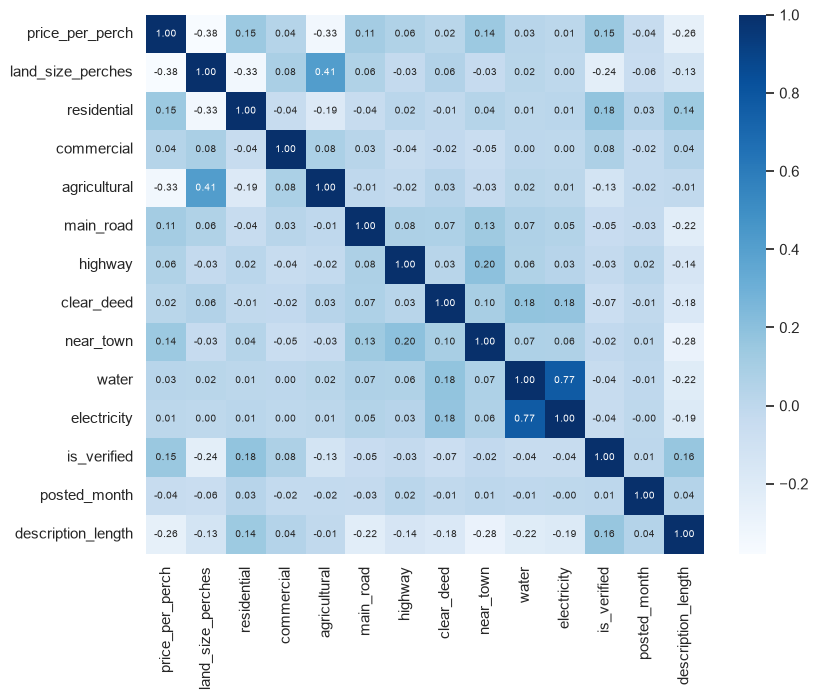

In [17]:
num_cols = ['price_per_perch', 'land_size_perches', 'residential', 'commercial', 'agricultural', 'main_road', 'highway', 'clear_deed',
            'near_town', 'water', 'electricity', 'is_verified', 'posted_month', 'description_length']
corr = df[num_cols].assign(price_per_perch=np.log(df['price_per_perch']), land_size_perches=np.log(df['land_size_perches'])).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', annot_kws={'size': 7})
plt.show()

In [18]:
df.groupby('posted_month')['price_per_perch'].agg(['size', 'median']).round(0)

,size,median
posted_month,,
1.0,6462,508500.0
2.0,5865,500000.0
3.0,3887,495000.0
4.0,219,785000.0
9.0,2,1067500.0
10.0,2167,405000.0
11.0,8217,450000.0
12.0,5154,455000.0


## 7. saving the cleaned data

only cleaning is done here. imputing, encoding and the models are in the next notebook.

In [19]:
os.makedirs('../data/processed', exist_ok=True)
out = df.drop(columns=['size_band', 'user']).assign(posted_date=df['posted_date'].dt.date)
out.to_csv('../data/processed/land_clean.csv', index=False)
print(out.shape)

(31973, 23)
